In [1]:
import sys, os
sys.path.append('../src')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import load
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve

a = pd.read_csv('../results/CICIDS2017_output_models.csv'); a.insert(0, 'dataset', 'CIC-IDS2017')
b = pd.read_csv('../results/UNSW_output_models.csv');       b.insert(0, 'dataset', 'UNSW-NB15')
both = pd.concat([a, b], ignore_index=True)
both.to_csv('../results/all_models_both_datasets.csv', index=False)
display(both)

,dataset,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us,train_s
0,CIC-IDS2017,RF default,0.9991,0.9963,0.9982,0.9973,1.0000,0.0008,0.0018,1.3874,119.2705
1,CIC-IDS2017,XGB default,0.9991,0.9947,0.9998,0.9973,1.0000,0.0011,0.0002,0.3083,8.1127
2,CIC-IDS2017,MLP,0.9799,0.9031,0.9869,0.9431,0.9989,0.0215,0.0131,0.6941,NaN
3,CIC-IDS2017,RF tuned,0.9990,0.9948,0.9993,0.9971,1.0000,0.0011,0.0007,2.5485,NaN
4,CIC-IDS2017,XGB tuned,0.9990,0.9943,0.9998,0.9970,1.0000,0.0012,0.0002,0.5935,NaN
5,UNSW-NB15,RF default,0.8126,0.6691,0.9431,0.7828,0.9513,0.2602,0.0569,3.0661,4.6000
6,UNSW-NB15,XGB default,0.8212,0.6807,0.9430,0.7907,0.9579,0.2467,0.0570,0.7160,0.8000
7,UNSW-NB15,RF tuned,0.7992,0.6488,0.9576,0.7735,0.9553,0.2891,0.0424,7.1337,11.5000
8,UNSW-NB15,XGB tuned,0.8171,0.6731,0.9509,0.7883,0.9599,0.2575,0.0491,2.4597,4.3000
9,UNSW-NB15,MLP,0.7699,0.6144,0.9594,0.7491,0.9368,0.3358,0.0406,11.1425,58.6000


---

In [2]:
Xtr, ytr, Xte, yte, feats = load('../data/UNSW_output')
spw = (ytr == 0).sum() / (ytr == 1).sum()
xgb = XGBClassifier(tree_method='hist', eval_metric='logloss', scale_pos_weight=spw,
                    n_jobs=-1, random_state=42).fit(Xtr, ytr)
p = xgb.predict_proba(Xte)[:, 1]

fpr, tpr, thr = roc_curve(yte, p)
rows = []
for target in [0.01, 0.05, 0.10, 0.20]:
    k = np.searchsorted(fpr, target, side='right') - 1
    rows.append(dict(max_fpr=target, recall=round(tpr[k], 3), threshold=round(thr[k], 3)))
ops = pd.DataFrame(rows)
ops.to_csv('../results/UNSW_operating_points.csv', index=False)
display(ops)

,max_fpr,recall,threshold
0,0.01,0.683,0.944
1,0.05,0.788,0.830
2,0.10,0.846,0.726
3,0.20,0.919,0.563


---

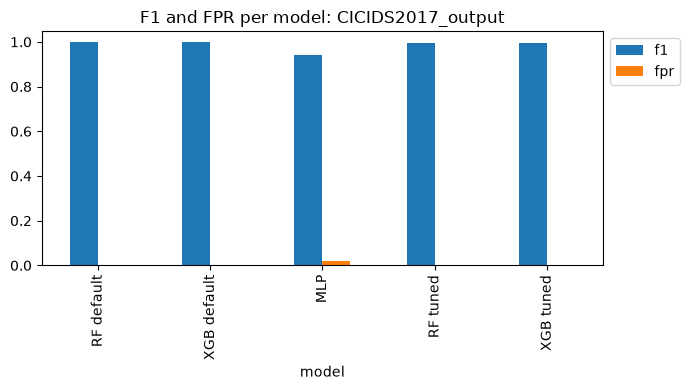

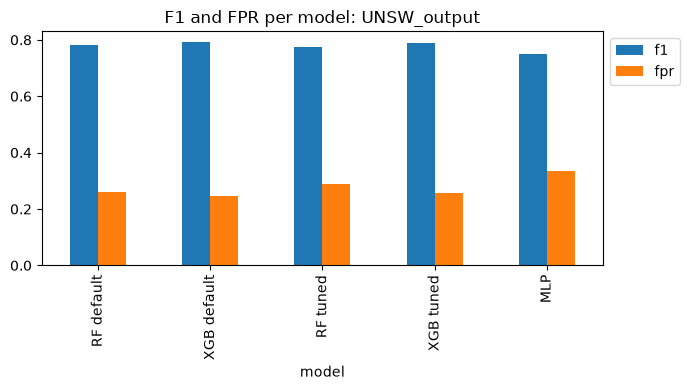

In [3]:
for name, d in [('CICIDS2017_output', a), ('UNSW_output', b)]:
    ax = d.set_index('model')[['f1', 'fpr']].plot.bar(figsize=(7, 4))
    plt.title('F1 and FPR per model: ' + name)
    plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
    plt.tight_layout()
    plt.savefig('../figures/f1_fpr_' + name + '.png', dpi=200, bbox_inches='tight')
    plt.show()

---

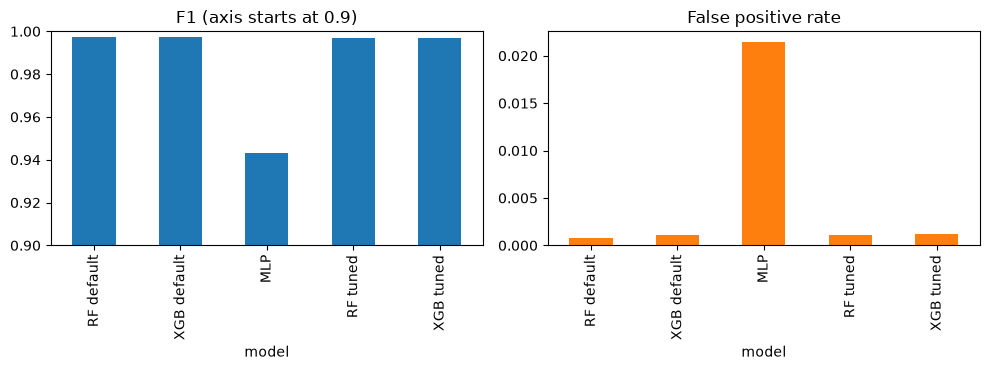

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
a.set_index('model')['f1'].plot.bar(ax=ax[0], ylim=(0.9, 1.0), title='F1 (axis starts at 0.9)')
a.set_index('model')['fpr'].plot.bar(ax=ax[1], color='tab:orange', title='False positive rate')
plt.tight_layout()
plt.savefig('../figures/f1_fpr_CICIDS2017_output.png', dpi=200, bbox_inches='tight'); plt.show()